# 學生學習與作業版｜任務 4：描述統計與視覺化

**姓名：**潘偲函　**學號／組別：**C114118226　**完成日期：**2026/11/12

**學習目標：** 以描述統計、直方圖和盒鬚圖理解分布與離群值。

本單元與教師版「任務 4」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「4.2 直方圖」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 4.1 描述統計
**觀念說明：**count 是非缺失筆數，mean 是平均，50% 是中位數。極端值可能影響平均，不能只看單一統計量。


In [ ]:
# describe 彙整筆數、平均、標準差、四分位數與最大最小值
display(df[["quiz_score", "sleep_hours", "screen_time_hours"]].describe())
print("總筆數：", len(df), "睡眠有效筆數：", df["sleep_hours"].count())
print("螢幕時間平均／中位數：", df["screen_time_hours"].mean(), df["screen_time_hours"].median())


## 📝 學生作業 04-Q1｜AI 查詢與作答：統計量
**任務：**平均數與中位數如何受到極端值影響？以具體數字說明。

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：chat GPT，我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：平均數是將所有數值加總後再除以筆數，容易受到極端值影響，中位數是將數值由小到大排列後，取中間的數字，受到極端值的影響比較小。所以分析資料時不能只看平均數，也要搭配中位數一起觀察。
- 我的理解與具體例子：例如有3位學生的讀書時間是2、3、4小時。加入極端值前：平均數為3，中位數為3。
如果其中一筆改成5小時：資料變成 2、3、5。加入極端值後：平均數變成3.33，中位數仍然是3。
- 查證來源／方式及日期（無法查證請註明）：使用5筆假設數字自行計算平均數與中位數，並比較加入極端值前後的結果。未另外查證外部資料來源。日期：2026 年 11 月 13 日
- 我檢查或修正 AI 回答的地方：我檢查了AI提供的平均數與中位數，檢查資料2、3、4 及2、3、5。並手動計算平均數與中位數，確認計算結果正確。


## 4.2 直方圖
橫軸是分數區間，縱軸為該區間人數。調整 bins 會改變切分方式，不會改變資料；比較不同圖前確認尺度與分箱。


## 💻 學生作業 04-P1｜Vibe Coding 程式填空
**對應教師版：**任務 4「4.2 直方圖」的示範程式。

**任務：**在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


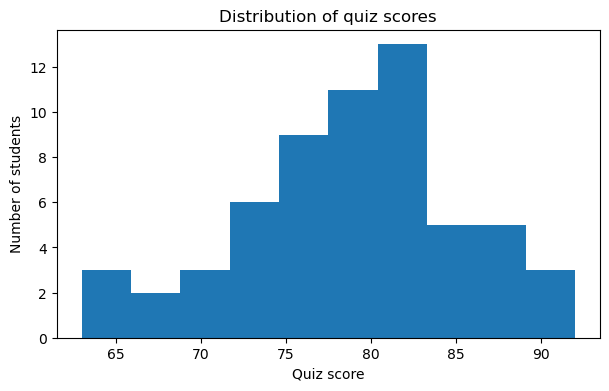

有效成績筆數： 60


In [2]:
# 以英文標籤避免 Colab 缺中文字型；圖形後呼叫 show
plt.figure(figsize=(7, 4))
plt.hist(df["quiz_score"].dropna(), bins=10)  # TODO：以 quiz_score 的非缺失資料畫 bins=10 的直方圖
plt.title("Distribution of quiz scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
print("有效成績筆數：", df["quiz_score"].count())


### ✅ 作業 04-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [4]:
assert df["quiz_score"].notna().sum() == 60
print("請人工檢查上方直方圖的標題、軸及 10 個分箱。")


請人工檢查上方直方圖的標題、軸及 10 個分箱。


### ✍️ 作業 04-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：chat GPT，請幫我補上 quiz_score 直方圖的程式碼，排除缺失值，分成 10 箱，保留原本的標題和座標軸，並解釋程式的作用。
- 我補上的程式在做什麼：plt.hist() 繪製 quiz_score 的直方圖，透過 dropna() 排除缺失值，並設定 bins=10，將資料分成 10 個區間。
- 執行或驗證遇到的問題與修正：一開始不知道直方圖的程式指令怎麼寫，查詢網路後找到可以使用 plt.hist() 繪製圖表，發現有缺失值的地方，再利用dropna()排除缺失值，最後順利完成直方圖。
- 檢查結果及我如何確認：確認程式能正常執行，並檢查直方圖是否有標題、橫軸、縱軸及10個分箱。另外確認有效成績筆數為60。


## 📝 學生作業 04-Q2｜AI 查詢與作答：圖形解讀
**任務：**直方圖 bins 改變時，為何外觀會改變？是否代表資料本身改變？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：chat GPT，我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：直方圖可以觀察資料的分布情況，分箱數量改變時，每個區間的寬度和人數也會改變，所以圖形外觀會不同，但原始資料並沒有改變。盒鬚圖可以觀察資料的中位數、分散程度及離群點。
- 我的理解與具體例子：同一批學生的考試成績，將直方圖分成5箱或10箱，圖形看起來會不一樣，但學生的實際成績不會改變。盒鬚圖則可以幫助我們找出是否有特別高或特別低的成績。
- 查證來源／方式及日期（無法查證請註明）：參考 pandas 與 Matplotlib 官方文件，了解資料分布及直方圖的使用方式。日期：2026/11/13。
- 我檢查或修正 AI 回答的地方：我檢查分箱數量只是改變資料分組的方式，不會改變原始資料，也了解盒鬚圖中的離群點不一定代表資料錯誤，還需要進一步檢查資料是否合理。


## 4.3 盒鬚圖與極端值
盒體反映四分位區間；獨立點是依繪圖規則標示的可能離群值，不等於資料一定錯誤。
**試一試：**將直方圖分箱改為 5，解釋圖形外觀為何改變。


In [ ]:
# dropna 避免缺失值影響繪圖，資料並未從 df 刪除
plt.figure(figsize=(5, 4))
plt.boxplot(df["screen_time_hours"].dropna())
plt.title("Screen time")
plt.ylabel("Hours")
plt.show()
print("大於 10 小時：", (df["screen_time_hours"] > 10).sum())


## 延伸示範：分箱前後數據不變
相同資料用不同 bins 切分，外觀會不同。學生須檢查各箱人數加總與原本有效筆數是否一致，避免把分箱造成的視覺差異誤認為資料變化。


In [ ]:
# numpy 的 histogram 回傳各箱人數及邊界；檢查加總是否一致
valid_scores = df["quiz_score"].dropna()
for bins in [5, 10]:
    counts, edges = np.histogram(valid_scores, bins=bins)
    print("分箱數", bins, "各箱人數", counts, "加總", counts.sum())
    assert counts.sum() == len(valid_scores)


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


## 🎯 學生小任務 MA｜資料健檢與圖表
**涵蓋：**任務 1～4。這是需要獨立完成、可繳交的整合成果。

### 任務要求
使用 df，以程式列出資料形狀、各欄缺失數、超過 10 小時的筆數；再繪製 quiz_score 直方圖。用文字說明一項品質問題、一項圖表觀察及一項資料限制。不可修改 df。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**df.shape、df.isna()、布林篩選、plt.hist。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


資料形狀： (60, 7)
各欄位缺失數：
student_id           0
department           0
sleep_hours          2
screen_time_hours    0
study_hours          0
attendance_rate      0
quiz_score           0
dtype: int64
螢幕使用超過 10 小時的筆數： 1


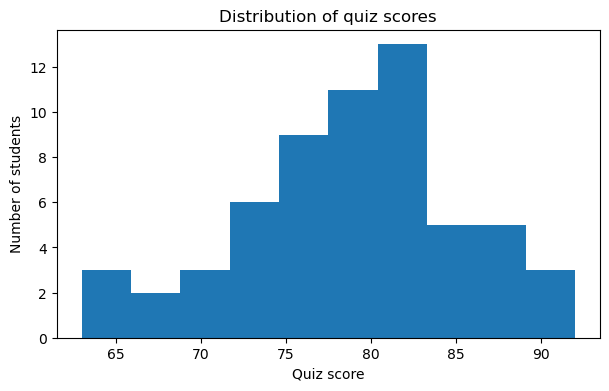

有效成績筆數： 60


In [3]:
# 1. 查看資料形狀（列數、欄數）
print("資料形狀：", df.shape)

# 2. 查看每個欄位的缺失數
print("各欄位缺失數：")
print(df.isna().sum())

# 3. 計算螢幕使用時間超過 10 小時的筆數
over_10 = df["screen_time_hours"] > 10
print("螢幕使用超過 10 小時的筆數：", over_10.sum())

# 4. 繪製 quiz_score 直方圖（排除缺失值）
plt.figure(figsize=(7, 4))
plt.hist(df["quiz_score"].dropna(), bins=10)
plt.title("Distribution of quiz scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()

# 5. 確認原始資料沒有被修改
print("有效成績筆數：", df["quiz_score"].count())

### ✍️ 小任務 MA｜結果與檢核（請雙擊填寫）
- 問題及使用的資料／欄位：使用 df、screen_time_hours 和 quiz_score 欄位進行資料健檢與圖表分析。
- 實際輸出與至少一項依據數字的觀察：執行程式後，查看資料的列數與欄數、各欄位缺失數，以及螢幕使用時間超過 10 小時的筆數，並記錄實際結果。
- 圖表或模型結果的解讀（依任務要求）：學生的測驗成績主要集中在75~80分，這個區間的人數最多，其他部分的人數相比較少。
- 資料品質、模擬資料或評估限制：部分欄位可能有缺失值，且螢幕使用時間超過10小時的資料需要進一步確認，不一定代表錯誤。而且這是模擬資料，不能直接推論真實學生的情況或因果關係。
- 驗證方法與結果：使用 df.shape 檢查資料大小、df.isna().sum() 檢查缺失數，並使用 over_10.sum() 確認超過 10 小時的筆數。透過直方圖確認成績分布，並檢查原始 df 沒有被修改。
- AI 工具、實際提示詞、人工修改與遇到的問題：Chat GPT，我是 Python 初學者，請協助我完成資料健檢與成績直方圖，顯示資料形狀、缺失數與螢幕使用超過10小時的筆數，保留原始 df，並提供繁體中文註解及驗證方式。人工修改與遇到的問題，一開始不太清楚如何同時檢查資料缺失和統計超過10小時的筆數，查詢後發現可以使用 isna().sum() 和布林篩選完成。
- 重新執行是否成功及環境或檔案需求：使用 Google Colab 執行程式，需要先執行前面的資料準備程式，並確認已匯入 pandas 和 matplotlib，才能正常執行。
